In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import sys
sys.path.append('../src')

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# JAX imports
import jax
import jax.numpy as jnp
import optax
from flax import nnx

# Scikit-learn imports
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import gen_batches

# Custom imports
from jaxrl.models.cnn import CNN

In [3]:
# Data
DATA_DIR = "../data"

# Model
N_IN = 1 # gray scale
N_OUT = 10 # classes

# Hyperparameters
LR = 0.001 # learning rate
BATCH_SIZE = 64
SEED = 0

# Random keys
main_key = jax.random.PRNGKey(SEED)
model_key, data_key = jax.random.split(main_key)

## Data

In [4]:
# 70,000 images of 28x28 pixels, flattened (784,).
# Train set 60,000, test set 10,000.
X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
X, y = X.astype(np.float32), y.astype(np.int32)

X_train_full, X_test = X[:60_000], X[60_000:]
y_train_full, y_test = y[:60_000], y[60_000:]

In [5]:
# Train/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, 
    test_size=10_000, 
    stratify=y_train_full, # same proportion of classes
    random_state=SEED
)

In [6]:
# A single mean and std over all pixels, estimated on the training set only
scaler = StandardScaler().fit(X_train.reshape(-1, 1))

def preprocess(X):
    """Standardize flat images and reshape them to NHWC, shape (N, 28, 28, 1)."""
    X = scaler.transform(X.reshape(-1, 1))
    return X.reshape(-1, 28, 28, 1)

X_train = preprocess(X_train)
X_val = preprocess(X_val)
X_test = preprocess(X_test)

In [7]:
# Convert to jax arrays
X_train, y_train = jnp.array(X_train), jnp.array(y_train)
X_val, y_val = jnp.array(X_val), jnp.array(y_val)
X_test, y_test = jnp.array(X_test), jnp.array(y_test)

JAX converts automatically. When a numpy array hits a jitted function, it's converted and transferred transparently. No explicit jnp.array() needed.

## Model

In [8]:
model = CNN(
    n_in=N_IN,
    n_out=N_OUT,
    rngs=nnx.Rngs(model_key)
)

In [9]:
# nnx.display(model)

## Optimizer

In [10]:
optimizer = nnx.Optimizer(
    model,
    tx=optax.adam(learning_rate=LR),
    wrt=nnx.Param # only apply the updates wrt to variables with type nnx.Param
)

## Training

In [11]:
@nnx.jit
def loss_fn(model, x, y):
    """Negative log likelihood (same as cross-entropy) loss."""
    # 1. Forward pass
    logits = model(x) # shape: (batch_size, num_classes)

    # 2. Compute the loss
    # optax computes -log(softmax(logits))[y] in one highly optimized step
    nll = optax.softmax_cross_entropy_with_integer_labels(logits=logits, labels=y) # shape: (batch_size,)
    loss = jnp.mean(nll) # a scalar
    return loss

In [12]:
# Flax NNX Training step
@nnx.jit
def train_step(model, optimizer, x, y):
    # 1-2. Forward pass and compute the loss and gradients
    loss, grads = nnx.value_and_grad(loss_fn)(model, x, y)
    # 3. Update the model parameters
    optimizer.update(model, grads)
    return loss

@nnx.jit
def eval_step(model, x, y):
    loss = loss_fn(model, x, y)
    return loss

@nnx.jit
def test_step(model, x):
    predictions = model.predict(x)
    return predictions

In [13]:
history = {
    'epoch': [],
    'train_loss': [],
    'val_loss': [],
}

for epoch in range(1, 10):
    
    history['epoch'].append(epoch)
    # 1. Train
    data_key, shuffle_key = jax.random.split(data_key)
    perm = jax.random.permutation(shuffle_key, len(X_train))
    train_losses = []
    for batch in gen_batches(len(X_train), BATCH_SIZE):
        idx = perm[batch]
        loss = train_step(model, optimizer, X_train[idx], y_train[idx])
        train_losses.append(loss)
    history['train_loss'].append(float(jnp.mean(jnp.stack(train_losses)))) 
    

    # 2. Evaluate on validation set
    val_losses = []
    for batch in gen_batches(len(X_val), BATCH_SIZE):
        loss = eval_step(model, X_val[batch], y_val[batch])
        val_losses.append(loss)
    history['val_loss'].append(float(jnp.mean(jnp.stack(val_losses))))

    print(f"Epoch {epoch}: Train Loss: {history['train_loss'][-1]:.4f}, Val Loss: {history['val_loss'][-1]:.4f}")

Could not load symbol cuStreamGetGreenCtx. Error: /lib/x86_64-linux-gnu/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx


Epoch 1: Train Loss: 0.1518, Val Loss: 0.0718
Epoch 2: Train Loss: 0.0516, Val Loss: 0.0546
Epoch 3: Train Loss: 0.0360, Val Loss: 0.0412
Epoch 4: Train Loss: 0.0252, Val Loss: 0.0355
Epoch 5: Train Loss: 0.0198, Val Loss: 0.0524
Epoch 6: Train Loss: 0.0171, Val Loss: 0.0422
Epoch 7: Train Loss: 0.0123, Val Loss: 0.0404
Epoch 8: Train Loss: 0.0105, Val Loss: 0.0423
Epoch 9: Train Loss: 0.0081, Val Loss: 0.0421


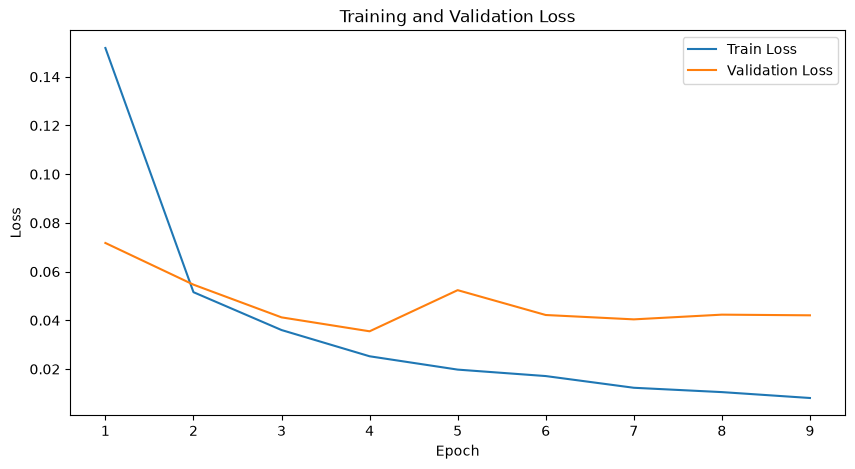

In [14]:
# Plot history
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history['epoch'], history['train_loss'], label='Train Loss')
ax.plot(history['epoch'], history['val_loss'], label='Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training and Validation Loss')
ax.legend()

In [15]:
correct_total = 0
for batch in gen_batches(len(X_test), BATCH_SIZE):
    preds = test_step(model, X_test[batch])
    correct_total += (preds == y_test[batch]).sum()
accuracy = correct_total / len(X_test)
print(f"Test accuracy: {accuracy * 100:.2f}%")

Test accuracy: 98.96%
